# Self-Organizing Maps (SOMs) Notebook - Alaska Cyclones
## Plot frequency changes by node and decade

**Notebook by Alice DuVivier - May 2026**

This Notebook reads in the pickle files saved as possible "winning" SOMs.

In [1]:
import pandas as pd
from minisom import MiniSom, asymptotic_decay
import xarray as xr
import cftime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import product
import cartopy
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from datetime import timedelta
from itertools import product
import seaborn as sns
import pickle
from scipy.stats import linregress,pearsonr, t, ttest_ind

In [2]:
# set path where the som finalist files are
dir_base = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/DATA/SOM_alaska_cyclones/'

## Load training data to interpret SOMs

In [3]:
# set input directory
dir_in = dir_base + 'som_training/'

In [4]:
def normalize_data(data):
    """
    Function for normalizing data prior to training using z-score
    """
    return (data - np.nanmean(data)) / np.nanstd(data)

In [5]:
# open file saved in earlier notebook (soms_antarctica-gettingdata.ipynb)
subset = xr.open_dataset(dir_in+'mesaclip_training_data_alaska_psl_autumn_decadal.nc')

# assign to numpy array object
subsetarray = subset['train_data'].values

# set data
data = normalize_data(subsetarray)

# set data input length
input_length = subsetarray.shape[1]    # using preprocessed data array; Number of the elements of the vectors in input.

## Set the parameter combinations for SOM finalists

In [6]:
# set paired values for possible winning maps based on Sammon maps evaluation
som_grid_rows    = [3, 4]    # (y-axis)
som_grid_cols    = [3, 4]    # (x-axis)
ranks            = [3, 45]
sigs             = [1.0, 1.0]
lrs              = [0.01, 0.005]
nitrs            = [250000, 50000]

## MANUAL CHANGING REQUIRED HERE ##
# select which set to plot
n = 0

In [7]:
# select info for input file (set above)
som_row = som_grid_rows[n]
som_col = som_grid_cols[n]
rank = ranks[n]
sig = sigs[n]
lr = lrs[n]
n_iter = nitrs[n]

In [8]:
# set the input name file from this
fin = 'som_alaska_psl_'+str(som_row)+'x'+str(som_col)+'_sig'+str(sig)+'_lr'+str(lr)+'_iter'+str(n_iter)
print(fin)

som_alaska_psl_3x3_sig1.0_lr0.01_iter250000


## Load pickles of "winning" combos and make assessment plots

In [9]:
# open pickle
with open(dir_in+'pickles/psl_som/'+fin+'.p', 'rb') as infile:
    som = pickle.load(infile)

In [10]:
# double check qerror
qerr = som.quantization_error(data)
print('quantization error: '+str(qerr))

quantization error: 26.348131518266264


In [11]:
# create an empty dictionary using the rows and columns of SOM
keys = [i for i in product(range(som_row),range(som_col))]
winmap = {key: [] for key in keys}

In [12]:
# set frequencies
frequencies = 100.*((som.activation_response(data))/sum(sum(som.activation_response(data))))
#verify the total frequency is 100%
total = sum(sum(frequencies))

# grab the indices for the data within the SOM lattice
for i, x in enumerate(data):
    winmap[som.winner(x)].append(i) 

# create list of the dictionary keys
som_keys = list(winmap.keys())
print(f"Number of composite maps: {len(som_keys)}")
print(f"The rows and columns of the SOM lattice to use to grab SOM indexes:\n{[i for i in list(winmap.keys())]}")

Number of composite maps: 9
The rows and columns of the SOM lattice to use to grab SOM indexes:
[(0, 0), (0, 1), (0, 2), (1, 0), (1, 1), (1, 2), (2, 0), (2, 1), (2, 2)]


## Load frequency data with dates attached
- want to look at decadal and monthly changes

In [13]:
# set input directory
dir_in = dir_base + 'data_for_composites/'

In [14]:
# load data with dates attached
ds_times = xr.open_dataset(dir_in+'autumn_all_times_for_frequency_analysis.nc')

In [15]:
ds_times.dates

<xarray.DataArray 'dates' (time_all: 49410)>
array([cftime.DatetimeNoLeap(1949, 9, 1, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(1949, 9, 2, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(1949, 9, 3, 0, 0, 0, 0, has_year_zero=True), ...,
       cftime.DatetimeNoLeap(2091, 12, 29, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2091, 12, 30, 0, 0, 0, 0, has_year_zero=True),
       cftime.DatetimeNoLeap(2091, 12, 31, 0, 0, 0, 0, has_year_zero=True)],
      dtype=object)
Coordinates:
    lat      float64 ...
    lon      float64 ...
    time     (time_all) object ...
Dimensions without coordinates: time_all

## Get frequencies

In [16]:
# choose decades we'll look at
# these will become coordinate arrays
decades = list(range(1950,2100,10))
decade_names = ['1950','1960','1970','1980','1990','2000','2010','2020','2030','2040','2050','2060','2070','2080','2090']

months = list(range(9,13,1))
month_names = ['9','10','11','12']

nodes = list(range(0,len(som_keys),1))

### Look at total times possible by decade

In [17]:
# get all training times
all_times = ds_times.dates
all_yy = all_times.dt.year
all_mm = all_times.dt.month

In [18]:
# breakdown all data into decades

# make numpy array to fill with decadal info
all_times_dec_array = np.zeros([len(decades)])
all_times_months_dec_array = np.zeros([len(decades),len(months)])

for dec in decades:
    print('Getting Decadal dates for '+str(dec)+'s')
    if dec == 1950:
        count = 0
    else:
        count = count+1
    # set the start and end years for this decade
    yy_st = dec - 1
    yy_ed = dec + 2
    yy = list(range(yy_st,yy_ed,1))
    #print(yy)
    # get number of data points for this range
    temp = all_times.isel(time_all = all_times.time.dt.year.isin([yy]))
    all_times_dec_array[count] = len(temp)
    # loop through months
    for mon in months:
        #print(mon)
        if mon == 9:
            m_count = 0
        else: 
            m_count = m_count+1
        # get number of points for this month
        temp2 = temp.isel(time_all = temp.time.dt.month.isin([mon]))
        all_times_months_dec_array[count,m_count] = len(temp2)

Getting Decadal dates for 1950s
Getting Decadal dates for 1960s
Getting Decadal dates for 1970s
Getting Decadal dates for 1980s
Getting Decadal dates for 1990s
Getting Decadal dates for 2000s
Getting Decadal dates for 2010s
Getting Decadal dates for 2020s
Getting Decadal dates for 2030s
Getting Decadal dates for 2040s
Getting Decadal dates for 2050s
Getting Decadal dates for 2060s
Getting Decadal dates for 2070s
Getting Decadal dates for 2080s
Getting Decadal dates for 2090s


In [19]:
# make numpy arrays to fill with frequencies
node_frac_all_array = np.zeros([len(som_keys)])
node_frac_dec_array = np.zeros([len(som_keys),len(decades)])
node_frac_mon_dec_array = np.zeros([len(som_keys),len(decades),len(months)])

# loop through the different som nodes
#for map_num in nodes[0:1]:
for map_num in nodes:
    print('getting frequencies for node '+str(map_num))
    # get indices of training data that mapped to this node
    inds = winmap[som_keys[map_num]]
    freq = 100.*(len(inds)/len(all_times.time))
    node_frac_all_array[map_num] = freq
    #print('total frequency of this node over all times: '+str(freq))
    # grab the training time metadata
    ds_sub = all_times.isel(time_all=inds)
    time_sub = ds_sub.time

    # loop through each decade
    #for dec in decades[0:1]:
    for dec in decades:
        #print('Getting Decadal dates for '+str(dec)+'s')
        if dec == 1950:
            d_count = 0
        else:
            d_count = d_count+1    
        # set the start and end years for this decade
        yy_st = dec - 1
        yy_ed = dec + 2
        yy = list(range(yy_st,yy_ed,1))
        #print(yy)
        # get total times for this decade and all nodes
        all_times_dec = len(all_times.isel(time_all = all_times.time.dt.year.isin([yy])))    
        # get total times for this decade and this node
        node_times_dec = len(time_sub.isel(time_all = time_sub.time.dt.year.isin([yy])))
        # now get frequency of this node for this decade (all months)
        freq = 100.*(node_times_dec/all_times_dec)
        node_frac_dec_array[map_num,d_count] = freq
        
        # subset these times so that we can do monthly analysis
        temp_all = all_times.isel(time_all = all_times.time.dt.year.isin([yy]))
        temp_node = time_sub.isel(time_all = time_sub.time.dt.year.isin([yy]))

        # loop through each month
        #for mon in months[0:1]:
        for mon in months:
            #print(mon)
            if mon == 9:
                m_count = 0
            else: 
                m_count = m_count+1
            # get total times for this decade and all nodes
            all_times_mon = len(temp_all.isel(time_all = temp_all.time.dt.month.isin([mon])))
            # get total times for this decade and this node
            node_times_mon = len(temp_node.isel(time_all = temp_node.time.dt.month.isin([mon])))
            # now get frequency of this node for this decade and this month
            freq = 100.*(node_times_mon/all_times_mon)
            node_frac_mon_dec_array[map_num,d_count,m_count] = freq

getting frequencies for node 0
getting frequencies for node 1
getting frequencies for node 2
getting frequencies for node 3
getting frequencies for node 4
getting frequencies for node 5
getting frequencies for node 6
getting frequencies for node 7
getting frequencies for node 8


In [20]:
print(node_frac_all_array.shape)
print(node_frac_dec_array.shape)
print(node_frac_mon_dec_array.shape)

(9,)
(9, 15)
(9, 15, 4)


In [21]:
# convert the numpy array to a xarray
node_frac_all = xr.DataArray(node_frac_all_array,dims=('node'))
node_frac_dec = xr.DataArray(node_frac_dec_array,dims=('node','decade'))
node_frac_mon_dec = xr.DataArray(node_frac_mon_dec_array,dims=('node','decade','month'))

In [22]:
# set coordinate arrays
node_frac_all['node'] = nodes

node_frac_dec['node'] = nodes
node_frac_dec['decade'] = decade_names

node_frac_mon_dec['node'] = nodes
node_frac_mon_dec['decade'] = decade_names
node_frac_mon_dec['month'] = month_names

In [23]:
# check the frequencies
print(sum(node_frac_all))
print(sum(node_frac_dec))
#print(sum(node_frac_dec.sel(decade='1980')))
print(sum(node_frac_mon_dec))
#print(sum(node_frac_mon_dec.sel(decade='1980',month='7')))

<xarray.DataArray ()>
array(100.)
Coordinates:
    node     int64 8
<xarray.DataArray (decade: 15)>
array([100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
       100., 100., 100., 100.])
Coordinates:
  * decade   (decade) <U4 '1950' '1960' '1970' '1980' ... '2070' '2080' '2090'
    node     int64 8
<xarray.DataArray (decade: 15, month: 4)>
array([[100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.],
       [100., 100., 100., 100.]])
Coordinates:
  * decade   (decade) <U4 '1950' '1960' '1970' '1980' ... '2070' '2080' '2090'
  * month    (month) <U2 '9' '10' '11' '12'
    node

### Calculate trends in frequencies

In [25]:
# set significance value
psig = 0.05

In [24]:
# test this simply for first node and total frequencies
n = 0

x = decades
y = node_frac_dec.isel(node=n)
regobj = linregress(x,y)
#print(regobj)
print('rate = '+str(regobj.slope)+' %/decade')
print('r2='+str((regobj.rvalue*regobj.rvalue)))

rate = 0.008467776910399866 %/decade
r2=0.14798193114049468


In [38]:
# loop through each pattern, and month to get trends

# make numpy arrays to fill with frequencies
node_trend_array = np.zeros([len(som_keys),4])
node_trend_mon_array = np.zeros([len(som_keys),len(months),4])

# loop through the different som nodes
for index, nn in enumerate(nodes):
#for index, nn in enumerate(nodes[0:1]):
    print('getting frequency trends for node '+str(nn))
    # get data to find trends for
    x = decades
    y = node_frac_dec.isel(node=index)
    regobj = linregress(x,y)
    # save the trend data - slope, r2, and p values
    node_trend_array[index,0] = regobj.slope
    node_trend_array[index,1] = regobj.pvalue
    # flag for if the trend is significant (1) or not (0)
    if (regobj.pvalue <= psig):
        node_trend_array[index,2] = 1
    else:
        node_trend_array[index,2] = 0
    # r2
    node_trend_array[index,3] = regobj.rvalue * regobj.rvalue    

    # now loop through each month to get those values as well
    for m_index, mm in enumerate(months):
    #for m_index, mm in enumerate(months[0:1]):
        #print('getting frequency trends for month '+str(mm))
        # get data to find trends for
        x = decades
        y = node_frac_mon_dec.isel(node=index,month=m_index)
        regobj = linregress(x,y)
        # save the trend data - slope, r2, and p values
        node_trend_mon_array[index,m_index,0] = regobj.slope
        node_trend_mon_array[index,m_index,1] = regobj.pvalue
        # flag for if the trend is significant (1) or not (0)
        if (regobj.pvalue <= psig):
            node_trend_mon_array[index,m_index,2] = 1
        else:
            node_trend_mon_array[index,m_index,2] = 0
        # r2
        node_trend_mon_array[index,m_index,3] = regobj.rvalue * regobj.rvalue    

# convert the numpy array to a xarray
node_trends_dec = xr.DataArray(node_trend_array,dims=('node','stat'))
node_trends_mon_dec = xr.DataArray(node_trend_mon_array,dims=('node','month','stat'))

# set coordinate arrays
node_trends_dec['node'] = nodes
node_trends_dec['stat'] = ['slope','pvalue','psig','r2']

node_trends_mon_dec['node'] = nodes
node_trends_mon_dec['month'] = month_names
node_trends_mon_dec['stat'] = ['slope','pvalue','psig','r2']

getting frequency trends for node 0
getting frequency trends for node 1
getting frequency trends for node 2
getting frequency trends for node 3
getting frequency trends for node 4
getting frequency trends for node 5
getting frequency trends for node 6
getting frequency trends for node 7
getting frequency trends for node 8


In [62]:
print('data for all months')
node_trends_dec.round(decimals=2)

data for all months


<xarray.DataArray (node: 9, stat: 4)>
array([[ 0.01,  0.16,  0.  ,  0.15],
       [-0.02,  0.01,  1.  ,  0.43],
       [-0.03,  0.  ,  1.  ,  0.68],
       [ 0.03,  0.  ,  1.  ,  0.78],
       [-0.  ,  0.63,  0.  ,  0.02],
       [-0.  ,  0.19,  0.  ,  0.13],
       [ 0.02,  0.  ,  1.  ,  0.58],
       [ 0.  ,  0.51,  0.  ,  0.03],
       [-0.01,  0.01,  1.  ,  0.39]])
Coordinates:
  * node     (node) int64 0 1 2 3 4 5 6 7 8
  * stat     (stat) <U6 'slope' 'pvalue' 'psig' 'r2'

In [63]:
print('data for september')
node_trends_mon_dec.isel(month=0).round(decimals=2)

data for september


<xarray.DataArray (node: 9, stat: 4)>
array([[ 0.  ,  0.76,  0.  ,  0.01],
       [-0.01,  0.1 ,  0.  ,  0.19],
       [-0.01,  0.16,  0.  ,  0.15],
       [ 0.05,  0.  ,  1.  ,  0.65],
       [-0.01,  0.2 ,  0.  ,  0.12],
       [-0.02,  0.19,  0.  ,  0.13],
       [ 0.02,  0.07,  0.  ,  0.23],
       [-0.02,  0.18,  0.  ,  0.14],
       [-0.01,  0.38,  0.  ,  0.06]])
Coordinates:
  * node     (node) int64 0 1 2 3 4 5 6 7 8
    month    <U2 '9'
  * stat     (stat) <U6 'slope' 'pvalue' 'psig' 'r2'

In [64]:
print('data for october')
node_trends_mon_dec.isel(month=1).round(decimals=2)

data for october


<xarray.DataArray (node: 9, stat: 4)>
array([[ 0.01,  0.21,  0.  ,  0.12],
       [-0.02,  0.14,  0.  ,  0.16],
       [-0.01,  0.04,  1.  ,  0.29],
       [ 0.02,  0.11,  0.  ,  0.18],
       [-0.01,  0.14,  0.  ,  0.16],
       [ 0.  ,  0.63,  0.  ,  0.02],
       [ 0.03,  0.  ,  1.  ,  0.47],
       [-0.01,  0.58,  0.  ,  0.02],
       [-0.02,  0.05,  1.  ,  0.27]])
Coordinates:
  * node     (node) int64 0 1 2 3 4 5 6 7 8
    month    <U2 '10'
  * stat     (stat) <U6 'slope' 'pvalue' 'psig' 'r2'

In [65]:
print('data for november')
node_trends_mon_dec.isel(month=2).round(decimals=2)

data for november


<xarray.DataArray (node: 9, stat: 4)>
array([[ 0.02,  0.31,  0.  ,  0.08],
       [-0.01,  0.37,  0.  ,  0.06],
       [-0.05,  0.  ,  1.  ,  0.55],
       [ 0.02,  0.06,  0.  ,  0.24],
       [ 0.  ,  0.7 ,  0.  ,  0.01],
       [ 0.01,  0.46,  0.  ,  0.04],
       [ 0.01,  0.19,  0.  ,  0.13],
       [ 0.02,  0.09,  0.  ,  0.21],
       [-0.02,  0.02,  1.  ,  0.34]])
Coordinates:
  * node     (node) int64 0 1 2 3 4 5 6 7 8
    month    <U2 '11'
  * stat     (stat) <U6 'slope' 'pvalue' 'psig' 'r2'

In [66]:
print('data for december')
node_trends_mon_dec.isel(month=3).round(decimals=2)

data for december


<xarray.DataArray (node: 9, stat: 4)>
array([[ 0.  ,  0.98,  0.  ,  0.  ],
       [-0.02,  0.01,  1.  ,  0.39],
       [-0.05,  0.01,  1.  ,  0.43],
       [ 0.02,  0.05,  1.  ,  0.27],
       [ 0.01,  0.16,  0.  ,  0.14],
       [-0.01,  0.35,  0.  ,  0.07],
       [ 0.03,  0.01,  1.  ,  0.45],
       [ 0.02,  0.05,  0.  ,  0.26],
       [ 0.01,  0.46,  0.  ,  0.04]])
Coordinates:
  * node     (node) int64 0 1 2 3 4 5 6 7 8
    month    <U2 '12'
  * stat     (stat) <U6 'slope' 'pvalue' 'psig' 'r2'

## Plot the results

In [46]:
# set output directory
dir_out = '/glade/campaign/cgd/ppc/duvivier/arctic_actionable/SOM_alaska_cyclones/analysis_v3/'
fout = 'figure_3_som_alaska_frequency_'
print(fout)

figure_3_som_alaska_frequency_


In [47]:
# set node names
node_names = ['0a', '0b', '0c', '1a', '1b', '1c', '2a', '2b', '2c']

In [48]:
# set xtick locations and labels
xlocs = [1950,2000,2050]
xlabels = ['Early','Mid','Late']

### Make Plots

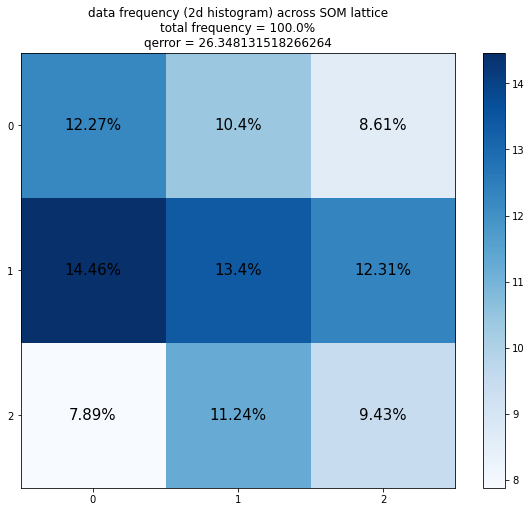

In [49]:
# Plot frequencies across SOM lattice over all times

fig = plt.figure(figsize=(10,8))
ax = plt.subplot(111)
im = ax.imshow(frequencies, cmap='Blues')   
    
# Loop over data dimensions and create text annotations in each cell
len_x, len_y = frequencies.shape
for i in range(len_x):
    for j in range(len_y):
        text = ax.text(j, i, str(round(frequencies[i, j],2))+'%', fontsize=15,
                       ha="center", va="center", color="k")

# Make cosmetic changes
cbar = plt.colorbar(im)
plt.title(r"data frequency (2d histogram) across SOM lattice" "\n" r"total frequency = "+str(total)+"%" "\n" r"qerror = "+str(qerr), fontsize=12)
plt.xticks(np.arange(0,som_row, 1))
plt.yticks(np.arange(0,som_col, 1))
    
# save figure
file_out = fout+'_alltimes.png'
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)

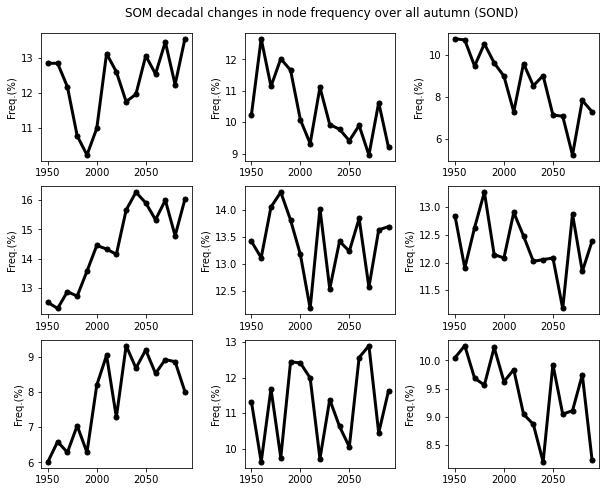

In [50]:
# Plot the frequency by decade over all months

# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, figsize=(10,8))
    
# loop through the different nodes to get the frequency for individual nodes
for map_num in range(len(som_keys)): 
    # make line plot of the frequencies
    cs = axs[som_keys[map_num][0],som_keys[map_num][1]].plot(decades,node_frac_dec.sel(node=map_num),
                                                             color='black',linestyle='-', linewidth=3,
                                                             marker='o', markersize=5)
    # set labeling/titles
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_ylabel('Freq.(%)',fontsize=10)

# finalize figure 
plt.suptitle('SOM decadal changes in node frequency over all autumn (SOND)', fontsize=12, x=0.515, y=0.925)
fig.subplots_adjust(wspace=0.35)

# save figure
file_out = fout+'_decadal.png'
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)


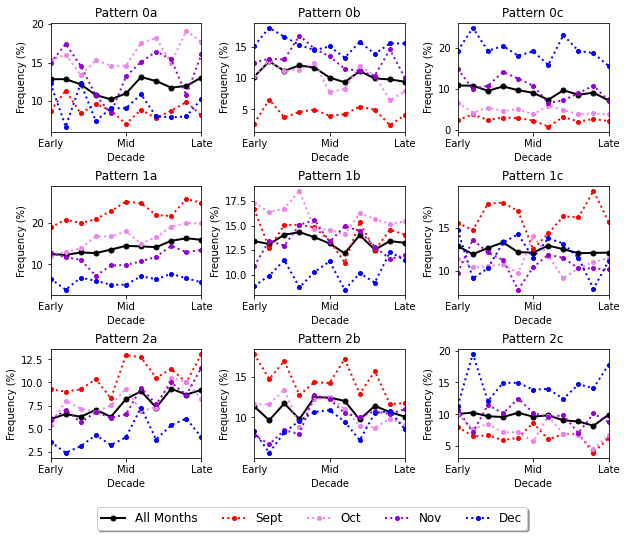

In [51]:
# Plot the frequency by decade over all month in the dataset

# set some of the plot info
fig, axs = plt.subplots(som_row, som_col, figsize=(10,8))
    
# loop through the different nodes to get the frequency for individual nodes
for map_num in range(len(som_keys)): 
    # make line plot of the frequencies
    ls0, = axs[som_keys[map_num][0],som_keys[map_num][1]].plot(decades,node_frac_dec.sel(node=map_num),
                                                             color='black',linestyle='-', linewidth=2,
                                                             marker='o', markersize=5)
    ls1, = axs[som_keys[map_num][0],som_keys[map_num][1]].plot(decades,node_frac_mon_dec.sel(node=map_num,month='9'),
                                                             color='red',linestyle=':', linewidth=2,
                                                             marker='o', markersize=4)
    ls2, = axs[som_keys[map_num][0],som_keys[map_num][1]].plot(decades,node_frac_mon_dec.sel(node=map_num,month='10'),
                                                             color='violet',linestyle=':', linewidth=2,
                                                             marker='o', markersize=4)
    ls3, = axs[som_keys[map_num][0],som_keys[map_num][1]].plot(decades,node_frac_mon_dec.sel(node=map_num,month='11'),
                                                             color='darkviolet',linestyle=':', linewidth=2,
                                                             marker='o', markersize=4)
    ls4, = axs[som_keys[map_num][0],som_keys[map_num][1]].plot(decades,node_frac_mon_dec.sel(node=map_num,month='12'),
                                                             color='blue',linestyle=':', linewidth=2,
                                                             marker='o', markersize=4)
    
    # set labeling/titles
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_title('Pattern '+node_names[map_num], loc="center",fontsize=12)
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_ylabel('Frequency (%)')
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_xlabel('Decade')
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_xticks(xlocs)
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_xlim(1950,2050)
    axs[som_keys[map_num][0],som_keys[map_num][1]].set_xticklabels(labels=xlabels)

# add legend
axs[som_keys[map_num][0],som_keys[map_num][1]].legend([ls0,ls1,ls2,ls3,ls4],
                                                      ['All Months','Sept','Oct','Nov','Dec'],
                                                      ncol=5, bbox_to_anchor=(0.5,-0.4),
                                                      fancybox=True, shadow=True, fontsize=12)

# finalize figure 
#plt.suptitle('Pattern frequency by decade', fontsize=12, x=0.515, y=0.95)
#fig.subplots_adjust(wspace=0.35)
fig.subplots_adjust(wspace=0.35)
fig.subplots_adjust(hspace=0.5)

# save figure
file_out = fout+'_decadal_by_month.png'
plt.savefig(fout, bbox_inches='tight', dpi=200)
plt.savefig(dir_out+file_out, bbox_inches='tight', dpi=200)